# Time-Series Econometrics in Python

A compact walkthrough of core econometric tools, implemented with `numpy` and `statsmodels`.
Each section simulates data with **known** properties, so every test result can be checked against the truth.

**Contents**
1. OLS from first principles (slope, RSS, TSS, R²)
2. Residual autocorrelation (Breusch–Godfrey test)
3. Stationarity: white noise, random walks, ADF test, differencing
4. Spurious regression
5. ARMA processes, ACF/PACF and ARIMA estimation
6. Cointegration (Engle–Granger) and the Error-Correction Model
7. VAR: lag selection, Granger causality, forecasting

*Author: Siva — M.Sc. Quantitative Finance, Kiel University*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (9, 3.5)
SEED = 1
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. OLS from first principles

For a simple regression $y = \beta_0 + \beta_1 x + u$, the OLS slope is
$\hat\beta_1 = \widehat{\text{Cov}}(x,y) / \widehat{\text{Var}}(x)$.
Both moments must use the **same** degrees-of-freedom correction — mixing `np.var` (divides by *n*) with `np.cov` (divides by *n − 1*) gives a wrong slope.

In [2]:
study_hours = np.array([1, 2, 3, 4, 5])
marks       = np.array([40, 50, 60, 70, 80])

var_x  = np.var(study_hours, ddof=1)            # sample variance, n-1
cov_xy = np.cov(study_hours, marks, ddof=1)[0, 1]
beta_1 = cov_xy / var_x
beta_0 = marks.mean() - beta_1 * study_hours.mean()

print(f"Var(x) = {var_x:.2f},  Cov(x,y) = {cov_xy:.2f}")
print(f"OLS: marks = {beta_0:.1f} + {beta_1:.1f} * hours")

# cross-check against statsmodels
print(sm.OLS(marks, sm.add_constant(study_hours)).fit().params)

Var(x) = 2.50,  Cov(x,y) = 25.00
OLS: marks = 30.0 + 10.0 * hours
[30. 10.]


**Goodness of fit.** $R^2 = 1 - \text{RSS}/\text{TSS}$: the share of the variation in $y$ explained by the model.

In [3]:
actual    = np.array([50, 60, 70, 80])
predicted = np.array([52, 61, 69, 79])

residuals = actual - predicted
rss = np.sum(residuals**2)
tss = np.sum((actual - actual.mean())**2)
print(f"Residuals: {residuals}")
print(f"RSS = {rss},  TSS = {tss},  R² = {1 - rss/tss:.4f}")

Residuals: [-2 -1  1  1]
RSS = 7,  TSS = 500.0,  R² = 0.9860


## 2. Residual autocorrelation — Breusch–Godfrey test

With time-series data, regression errors are often correlated over time. Then OLS standard errors are wrong.
Positive autocorrelation shows up as long runs of same-signed residuals; negative autocorrelation as constant sign-switching.

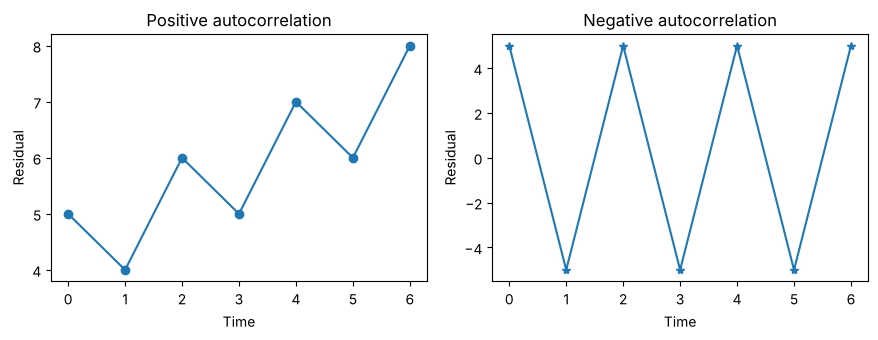

In [4]:
positive = np.array([5, 4, 6, 5, 7, 6, 8])
negative = np.array([5, -5, 5, -5, 5, -5, 5])

fig, ax = plt.subplots(1, 2, sharey=False)
ax[0].plot(positive, marker="o"); ax[0].set_title("Positive autocorrelation")
ax[1].plot(negative, marker="*"); ax[1].set_title("Negative autocorrelation")
for a in ax: a.set_xlabel("Time"); a.set_ylabel("Residual")
plt.tight_layout(); plt.show()

The Breusch–Godfrey test regresses the residuals on their own lags. **H₀: no autocorrelation.**
Below, the errors are i.i.d. by construction, so we expect *not* to reject.

In [5]:
rng = np.random.default_rng(SEED)
x = np.arange(1, 101)
y = 5 + 2 * x + rng.normal(0, 10, 100)

ols = sm.OLS(y, sm.add_constant(x)).fit()
lm, lm_p, _, _ = acorr_breusch_godfrey(ols, nlags=1)
print(f"BG LM statistic = {lm:.3f},  p-value = {lm_p:.3f}")

BG LM statistic = 0.101,  p-value = 0.751


## 3. Stationarity and the ADF test

A series is (weakly) stationary if its mean, variance and autocovariances do not change over time.
- **White noise** $\varepsilon_t$ — stationary.
- **Random walk** $y_t = y_{t-1} + \varepsilon_t$ — non-stationary (unit root); shocks never die out.
- **Deterministic trend** $y_t = a + bt + \varepsilon_t$ — stationary around a trend line.

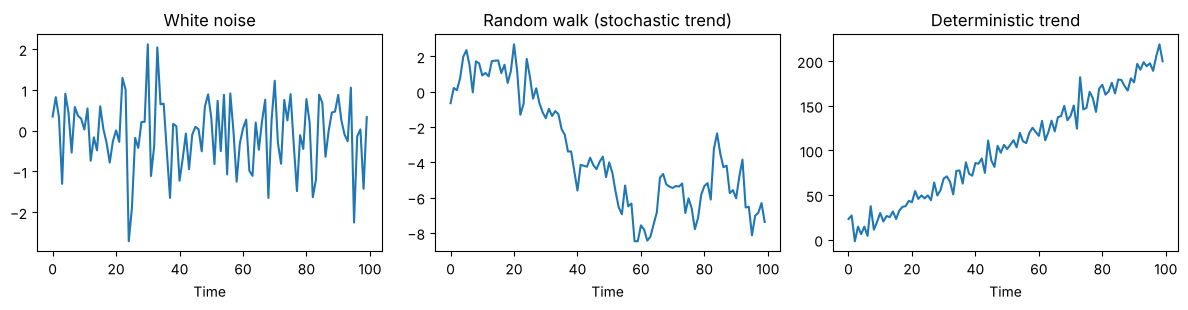

In [6]:
rng = np.random.default_rng(SEED)
n = 100
t = np.arange(n)
white_noise   = rng.normal(0, 1, n)
random_walk   = np.cumsum(rng.normal(0, 1, n))
deterministic = 5 + 2 * t + rng.normal(0, 10, n)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, s, title in zip(ax, [white_noise, random_walk, deterministic],
                       ["White noise", "Random walk (stochastic trend)", "Deterministic trend"]):
    a.plot(s); a.set_title(title); a.set_xlabel("Time")
plt.tight_layout(); plt.show()

**Augmented Dickey–Fuller test.** H₀: the series has a unit root (non-stationary).
A random walk should fail to reject; its first difference $\Delta y_t = \varepsilon_t$ should reject clearly.

In [7]:
diff_rw = np.diff(random_walk)

for name, s in [("Random walk", random_walk), ("Differenced random walk", diff_rw)]:
    stat, p, *_ = adfuller(s)
    verdict = "stationary" if p < 0.05 else "unit root not rejected"
    print(f"{name:26s} ADF = {stat:6.2f}   p = {p:.4f}   -> {verdict}")

Random walk                ADF =  -1.03   p = 0.7434   -> unit root not rejected
Differenced random walk    ADF =  -9.27   p = 0.0000   -> stationary


## 4. Spurious regression

Regressing one random walk on another **independent** random walk often gives a "significant" slope and a high R² — even though the two are unrelated.
This is why stationarity must be checked before interpreting a regression.

In [8]:
rng = np.random.default_rng(SEED)
x = np.cumsum(rng.normal(0, 1, 100))
y = np.cumsum(rng.normal(0, 1, 100))   # independent of x

spurious = sm.OLS(y, sm.add_constant(x)).fit()
print(f"slope = {spurious.params[1]:.3f},  t = {spurious.tvalues[1]:.2f},  R² = {spurious.rsquared:.3f}")
print(f"ADF p-values: x = {adfuller(x)[1]:.3f},  y = {adfuller(y)[1]:.3f}  (both non-stationary)")
print(f"Durbin–Watson of residuals = {sm.stats.durbin_watson(spurious.resid):.2f}  (far below 2 = warning sign)")

slope = 0.834,  t = 11.33,  R² = 0.567
ADF p-values: x = 0.826,  y = 0.743  (both non-stationary)
Durbin–Watson of residuals = 0.34  (far below 2 = warning sign)


## 5. ARMA processes and ARIMA estimation

| Process | Equation | ACF | PACF |
|---|---|---|---|
| AR(1) | $y_t = \phi y_{t-1} + \varepsilon_t$ | decays geometrically | cuts off after lag 1 |
| MA(1) | $y_t = \varepsilon_t + \theta \varepsilon_{t-1}$ | cuts off after lag 1 | decays |
| ARMA(1,1) | both | decays | decays |

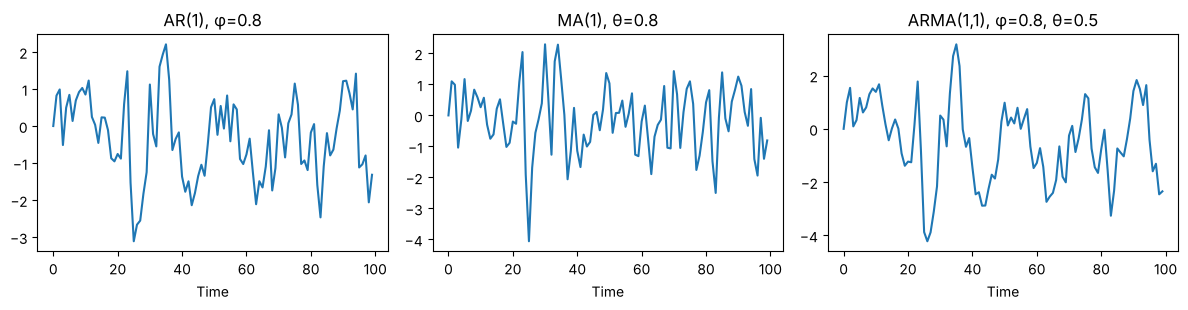

In [9]:
def simulate_arma(phi=0.0, theta=0.0, n=100, seed=SEED):
    rng = np.random.default_rng(seed)
    e = rng.normal(0, 1, n)
    y = np.zeros(n)
    for t in range(1, n):
        y[t] = phi * y[t-1] + e[t] + theta * e[t-1]
    return y

ar1  = simulate_arma(phi=0.8)
ma1  = simulate_arma(theta=0.8)
arma = simulate_arma(phi=0.8, theta=0.5)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, s, title in zip(ax, [ar1, ma1, arma], ["AR(1), φ=0.8", "MA(1), θ=0.8", "ARMA(1,1), φ=0.8, θ=0.5"]):
    a.plot(s); a.set_title(title); a.set_xlabel("Time")
plt.tight_layout(); plt.show()

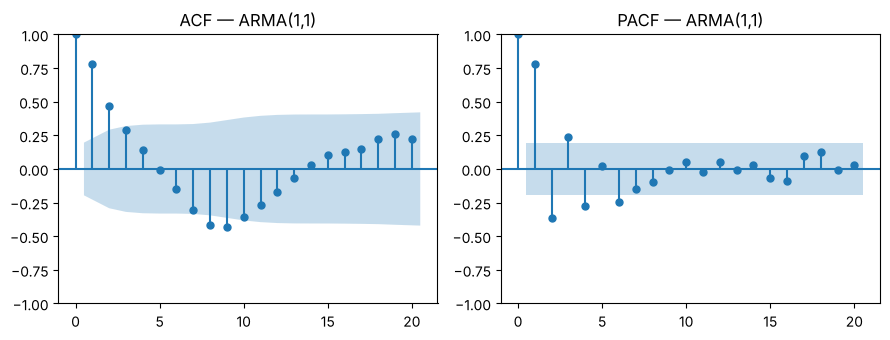

In [10]:
fig, ax = plt.subplots(1, 2)
plot_acf(arma, lags=20, ax=ax[0], title="ACF — ARMA(1,1)")
plot_pacf(arma, lags=20, ax=ax[1], title="PACF — ARMA(1,1)")
plt.tight_layout(); plt.show()

**Estimation.** The simulated series is stationary, so the correct specification is ARIMA(1,**0**,1).
Fitting ARIMA(1,1,1) *over-differences* the data — compare the AIC. (With only 100 observations the estimates are close to, but not exactly, the true values.)

In [11]:
fit_101 = ARIMA(arma, order=(1, 0, 1)).fit()
fit_111 = ARIMA(arma, order=(1, 1, 1)).fit()

print(fit_101.summary().tables[1])
print(f"\nTrue values: φ = 0.8, θ = 0.5")
print(f"AIC  ARIMA(1,0,1) = {fit_101.aic:.1f}   vs   ARIMA(1,1,1) = {fit_111.aic:.1f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4997      0.342     -1.463      0.144      -1.169       0.170
ar.L1          0.5762      0.102      5.654      0.000       0.376       0.776
ma.L1          0.6940      0.081      8.581      0.000       0.535       0.852
sigma2         0.6707      0.106      6.309      0.000       0.462       0.879

True values: φ = 0.8, θ = 0.5
AIC  ARIMA(1,0,1) = 253.6   vs   ARIMA(1,1,1) = 265.7


## 6. Cointegration and the Error-Correction Model

Two non-stationary series are **cointegrated** if a linear combination of them is stationary — they share a long-run equilibrium.

**Engle–Granger two-step:**
1. Estimate the long-run relation $y_t = \alpha + \beta x_t + u_t$ and test the residuals $\hat u_t$ for stationarity.
2. Estimate the ECM: $\Delta y_t = c + \gamma \Delta x_t + \lambda \hat u_{t-1} + e_t$.
   A negative $\lambda$ is the speed at which deviations from equilibrium are corrected.

*(Strictly, the residual ADF test should use Engle–Granger critical values — `statsmodels.tsa.stattools.coint` does this; shown below as a check.)*

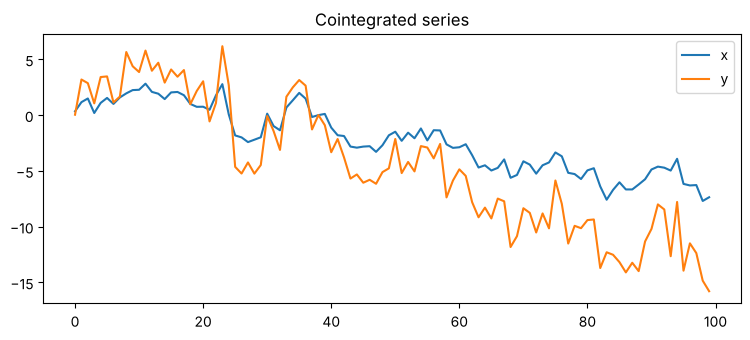

ADF p-values (levels):  x = 0.826,  y = 0.846
Long-run β̂ = 1.984  (true 2)
ADF p-value of residuals = 7.63e-16
Engle–Granger coint test p-value = 7.54e-15


In [12]:
from statsmodels.tsa.stattools import coint

rng = np.random.default_rng(SEED)
n = 100
x = np.cumsum(rng.normal(0, 1, n))       # random walk
y = 2 * x + rng.normal(0, 1, n)          # tied to x: true β = 2

plt.plot(x, label="x"); plt.plot(y, label="y")
plt.title("Cointegrated series"); plt.legend(); plt.show()

long_run = sm.OLS(y, sm.add_constant(x)).fit()
u_hat = long_run.resid

print(f"ADF p-values (levels):  x = {adfuller(x)[1]:.3f},  y = {adfuller(y)[1]:.3f}")
print(f"Long-run β̂ = {long_run.params[1]:.3f}  (true 2)")
print(f"ADF p-value of residuals = {adfuller(u_hat)[1]:.2e}")
print(f"Engle–Granger coint test p-value = {coint(y, x)[1]:.2e}")

In [13]:
ecm_data = pd.DataFrame({
    "dy":      np.diff(y),
    "dx":      np.diff(x),
    "ecm_lag": u_hat[:-1],      # u_{t-1} aligned with Δy_t
})
ecm = sm.OLS(ecm_data["dy"], sm.add_constant(ecm_data[["dx", "ecm_lag"]])).fit()
print(ecm.summary().tables[1])
print(f"\nAdjustment coefficient λ = {ecm.params['ecm_lag']:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0044      0.101      0.044      0.965      -0.197       0.206
dx             1.9562      0.118     16.521      0.000       1.721       2.191
ecm_lag       -1.1090      0.102    -10.848      0.000      -1.312      -0.906

Adjustment coefficient λ = -1.109


## 7. Vector Autoregression (VAR)

A VAR models several series jointly, each as a function of its own lags and the lags of the others.
Here *inflation* is built to depend on last period's *GDP*, so GDP should Granger-cause inflation.

In [14]:
rng = np.random.default_rng(SEED)
n = 100
gdp = np.cumsum(rng.normal(0, 1, n))
gdp_lag = pd.Series(gdp).shift(1)                 # proper lag (no wrap-around)
inflation = 0.5 * gdp_lag + rng.normal(0, 1, n)

data = pd.DataFrame({"GDP": gdp, "Inflation": inflation}).dropna()

var_model = VAR(data)
print(var_model.select_order(maxlags=5).summary())

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       2.345       2.399       10.43       2.367
1     -0.2255   -0.06313*      0.7982    -0.1599*
2    -0.2365*     0.03403     0.7895*     -0.1273
3     -0.2302      0.1486      0.7948    -0.07720
4     -0.1644      0.3226      0.8494     0.03228
5    -0.09110      0.5041      0.9149      0.1493
-------------------------------------------------


In [15]:
var_fit = var_model.fit(1)
print(var_fit.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 03, Nov, 2026
Time:                     12:01:03
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                 -0.0694496
Nobs:                     98.0000    HQIC:                 -0.163699
Log likelihood:          -260.954    FPE:                   0.796383
AIC:                    -0.227713    Det(Omega_mle):        0.749776
--------------------------------------------------------------------
Results for equation GDP
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const               -0.169339         0.109348           -1.549           0.121
L1.GDP               0.988634         0.047010           21.030           0.000
L1.Inflation        -0.051995         0.080293           -0.648   

**Granger causality.** H₀: lags of GDP do not help predict inflation. The second column is tested as the cause of the first.

In [16]:
gc = grangercausalitytests(data[["Inflation", "GDP"]], maxlag=1)
F, p = gc[1][0]["ssr_ftest"][:2]
print(f"GDP -> Inflation:  F = {F:.1f},  p = {p:.2e}")

GDP -> Inflation:  F = 87.0,  p = 4.48e-15


In [17]:
forecast = var_fit.forecast(data.values[-var_fit.k_ar:], steps=5)
pd.DataFrame(forecast, columns=["GDP_forecast", "Inflation_forecast"]).round(3)

,GDP_forecast,Inflation_forecast
0,-7.191,-3.586
1,-7.093,-3.584
2,-6.995,-3.534
3,-6.901,-3.487
4,-6.811,-3.441


*Note:* GDP here is a random walk, so a VAR in levels is used purely for illustration. With real data I would test for unit roots first and use differences or a VECM.

---
**Tools:** Python, NumPy, pandas, statsmodels, Matplotlib.